In [526]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import asyncio
import numpy as np
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

TRIVIA_QA_PATH = os.getenv('TRIVIA_QA_PATH')
Natural_Questions_PATH = os.getenv('Natural_Questions_PATH')
SQUAD_PATH = os.getenv('SQUAD_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2119]:
# Load all intermediate and final dataset files:
# Intermediate:
extracted_data = load_json(f"{REPO_PATH}\data_files\extracted_data.json")
processed_data = load_json(f"{REPO_PATH}\data_files\processed_data.json")
cluster_data = load_json(f"{REPO_PATH}\data_files\cluster_data.json")
# Final:
knowledge_maze_qa = load_json(f"{REPO_PATH}\data_files\knowledge_maze_qa.json")
knowledge_maze_paragraphs = load_json(f"{REPO_PATH}\data_files\knowledge_maze_paragraphs.json")

# 1. Load base datasets:
Load all three source datasets and structure them as question-answer pairs.

In [3]:
from knowledge_maze.create_dataset.load_datasets import load_data
load_data(f"{REPO_PATH}\data_files\extracted_data.json")

Processing SQuAD: 100%|████████████████████████████████████████████████████████████| 442/442 [00:00<00:00, 1002.85it/s]


Loaded 272007 question-answer pairs in total.


# 2. Data preprocess:
- Filter out problematic questions (long answers, answers within questions, complex questions)
- Classify answers by types of entities anf filter out irrelevant types
- Update entity types in the dataset

Filtering WH questions: 100%|██████████████████████████████████████████████| 272007/272007 [00:00<00:00, 421352.15it/s]


244638 out of 272007 samples have passed (89.9%).


Filtering self containing questions: 100%|█████████████████████████████████| 244638/244638 [00:02<00:00, 102244.55it/s]


242584 out of 244638 samples have passed (99.2%).


Filtering out long questions: 100%|███████████████████████████████████████| 242584/242584 [00:00<00:00, 1569093.82it/s]


...

9038 numerical samples found (4.0%).


Extracting date & time samples: 100%|██████████████████████████████████████| 226408/226408 [00:00<00:00, 508950.34it/s]


22159 date & time samples found (9.8%).


Extracting rest of the relevant samples: 100%|████████████████████████████| 226408/226408 [00:00<00:00, 2635084.87it/s]


88559 relevant samples found (39.1%).
Generating pie chart for 8 types...


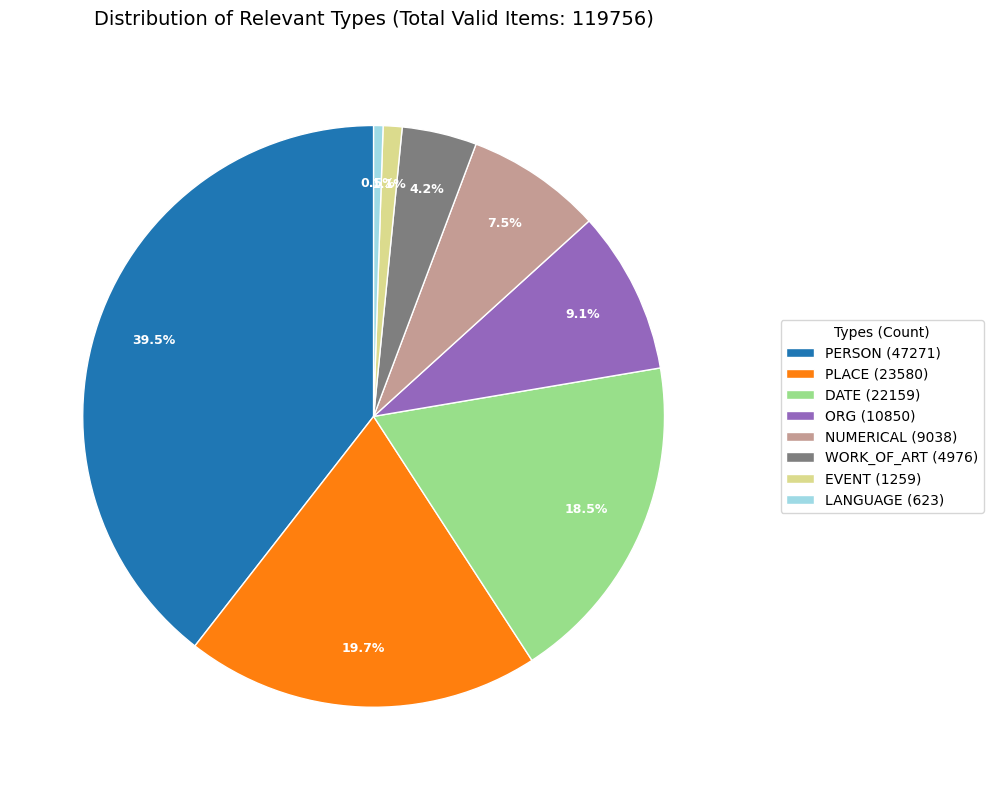

In [1101]:
from knowledge_maze.create_dataset.preprocess import preprocess
processed_data = preprocess(extracted_data, output_path=f"{REPO_PATH}\data_files\processed_data.json")

# 3. Group questions:
- Group Questions togather based on shared answers
- Questions with numerical and date answers are grouped by closed value answers instead of exact match
- Filter out questions that are too semantically similar
- Filter out ambiguous questions
- Create candidate reasoning chains for the dataset

Dividing data by type...
Creating reasoning paths for Date clusters...


Generating question embeddings: 100%|██████████████████████████████████████████████████| 11/11 [00:25<00:00,  2.29s/it]
Creating similarity graphs and filtering questions: 100%|█████████████████████████| 3095/3095 [00:06<00:00, 475.97it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████| 3095/3095 [00:00<00:00, 646547.01it/s]


Creating reasoning paths for Number clusters...


Generating question embeddings: 100%|████████████████████████████████████████████████████| 4/4 [00:11<00:00,  2.93s/it]
Creating similarity graphs and filtering questions: 100%|████████████████████████| 1056/1056 [00:01<00:00, 1051.78it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████| 1056/1056 [00:00<00:00, 374624.46it/s]


Creating reasoning paths for Place clusters...


Generating question embeddings: 100%|██████████████████████████████████████████████████| 12/12 [00:27<00:00,  2.33s/it]
Creating similarity graphs and filtering questions: 100%|█████████████████████████| 2162/2162 [00:02<00:00, 865.08it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████| 1736/1736 [00:00<00:00, 230903.52it/s]


Creating reasoning paths for General clusters...


Generating question embeddings: 100%|██████████████████████████████████████████████████| 15/15 [00:36<00:00,  2.41s/it]
Creating similarity graphs and filtering questions: 100%|████████████████████████| 4768/4768 [00:03<00:00, 1460.50it/s]
Splitting large clusters: 100%|███████████████████████████████████████████████| 4768/4768 [00:00<00:00, 1002277.43it/s]


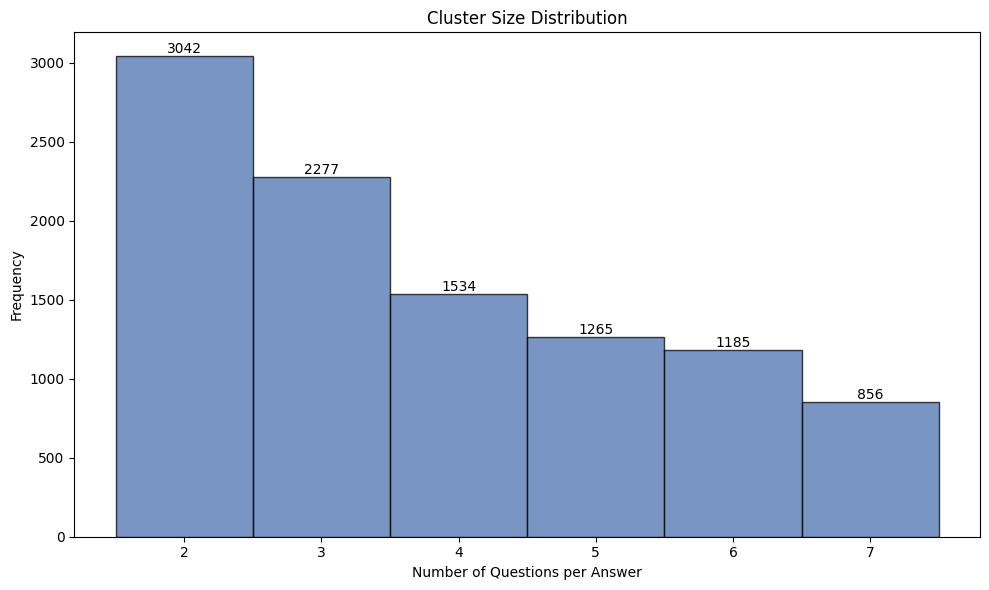

In [1346]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
cluster_data = await create_paths(processed_data, output_path=f"{REPO_PATH}\data_files\cluster_data.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 1/1 [00:02<00:00,  2.13s/it]

Answer: ('George Eliot', 'PERSON')
Questions before filtering:
1. Mary Anne Evans was the real name of which famous novelist?
2. What is the pen-name of novelist Mary Ann Evans (1819-80)?
3. English novelist Mary Anne Evans is better known by what name?


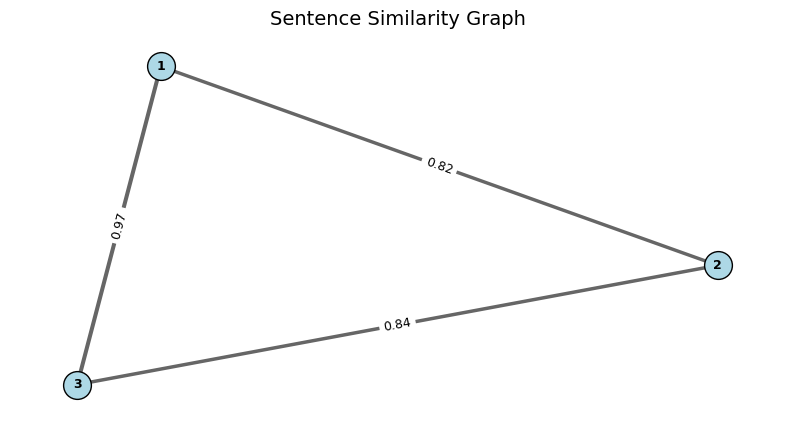

Questions after filtering:
1. English novelist Mary Anne Evans is better known by what name?


In [1142]:
# Plot graph example - (filtering process):
from knowledge_maze.create_dataset.create_reasoning_path import display_random_sample
display_random_sample(processed_data)

# 4. Create Structured Data:
- Split questions list into reasoning paths and extract main question
- Create counter-factual answers
- Assign paragraph ids for each question pair
- Make an organized data structure for later usage and display data samples efficiently

**Dataset QA Structure:**
```
{
    'ID': '',
    'Question': '',
    'Answers': {
        'Memory answer': '',
        'Counter answer 1': '',
        'Counter answer 2': '',
        'Distractor answer': ''
    },
    'Answer type': '',
    'Reasoning path 1':[
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        ...
    ],
    'Reasoning path 2':[
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        ...
    ]
    'Distractor paragraphs': []
}
```

Creating dataset QA samples: 100%|██████████████████████████████████████████████| 10159/10159 [00:30<00:00, 338.41it/s]


Generating counter answers for numerical data:


Usage cost: 0.0405$ (Estimated: 0.04$): 100%|██████████████████████████████████████| 1225/1225 [00:31<00:00, 38.54it/s]


Generating counter answers for general & place data:


Usage cost: 0.2754$ (Estimated: 0.28$): 100%|██████████████████████████████████████| 6394/6394 [02:36<00:00, 40.83it/s]


Generating counter answers for date data:


Usage cost: 0.0000$ (Estimated: 0.00$): 100%|██████████████████████████████████████| 2540/2540 [00:33<00:00, 75.23it/s]


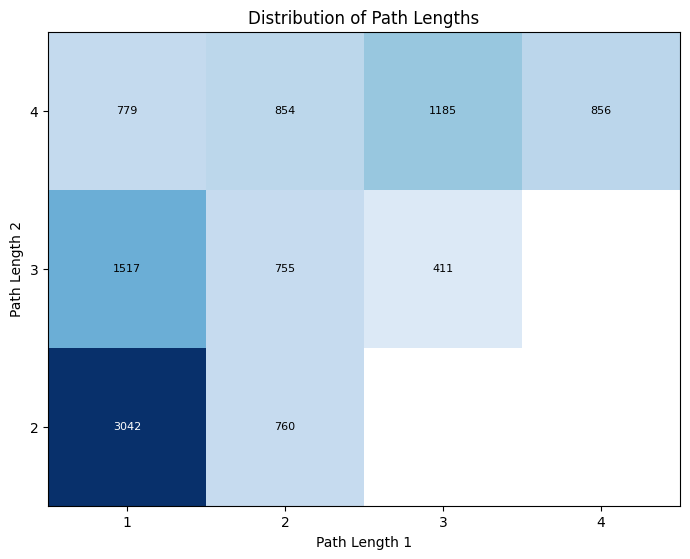

Aggregating question counts by type...
Generating stacked bar plot for 10159 samples...


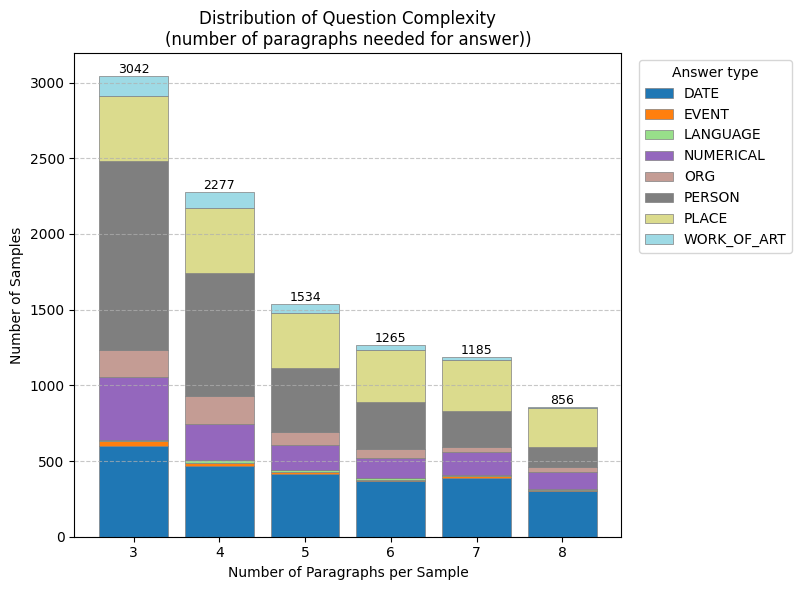

In [1347]:
from knowledge_maze.create_dataset.create_data_qa import create_data_qa
knowledge_maze_qa = await create_data_qa(cluster_data, output_path=f"{REPO_PATH}\data_files\knowledge_maze_qa.json")

In [1980]:
# Show random sample:
from knowledge_maze.create_dataset.create_data_qa import display_qa_sample
display_qa_sample(random.choice(knowledge_maze_qa))

ID: 091415e4-f4c1-4c23-a636-b7b7c76951b4
Question: What is the name of the empire Napoleon dissolved?
Answer (Original): the Holy Roman Empire
Answer type: PLACE

Answers:
- the Holy Roman Empire (Memory answer)
- the Byzantine Empire (Counter answer 1)
- the Ottoman Empire (Counter answer 2)
- the Spanish Empire (Distractor answer)

Sub-questions path 1:
 1. What is the name of the empire Napoleon dissolved? (the Holy Roman Empire)

Sub-questions path 2:
 1. What is the name of the empire Napoleon dissolved? (the Holy Roman Empire)
 2. What was the region covering modern Germany, southern Denmark, the Netherlands, Belgium, Luxembourg,
    Switzerland, Austria, Slovakia, Czech Republic and much of northern Italy known as? (the Holy Roman Empire)


# 5. Generate paragraphs:
- aa
- aa
- aa

In [2139]:
from knowledge_maze.create_dataset.create_paragraphs import create_paragraphs
knowledge_maze_paragraphs = await create_paragraphs(random.sample(knowledge_maze_qa, k=50), output_path=os.path.join(REPO_PATH, "data_files", "knowledge_maze_paragraphs.json"))

Processing 50 QA samples to extract and group paragraph info...
Generating 'Chain' paragraphs (grouped by Answer Type)...
--> Generating 31 paragraphs for type: 'PLACE'


Usage cost: 0.0058$ (Estimated: 0.01$): 100%|██████████████████████████████████████████| 31/31 [00:08<00:00,  3.62it/s]


--> Generating 28 paragraphs for type: 'PERSON'


Usage cost: 0.0042$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 28/28 [00:06<00:00,  4.20it/s]


--> Generating 25 paragraphs for type: 'DATE'


...

--> Generating 14 paragraphs for type: 'ORG'


Usage cost: 0.0023$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 14/14 [00:02<00:00,  5.31it/s]


--> Generating 100 'Edge' paragraphs...


Usage cost: 0.0115$ (Estimated: 0.01$): 100%|████████████████████████████████████████| 100/100 [00:08<00:00, 11.99it/s]

Combining generated paragraphs with IDs...
Saving paragraph data (231 entries) to C:\Users\Daniel\Desktop\KnowledgeMaze\data_files\knowledge_maze_paragraphs.json...
Save complete.


In [2206]:
# Show random paragraph sample:
from knowledge_maze.create_dataset.create_paragraphs import display_paragraph
p_id = random.choice(list(knowledge_maze_paragraphs.keys()))
display_paragraph(p_id)

Paragraph type: Edge

Question:
- What label became Detroit's most famous?

Original answer: Motown
Counter answer: Atlantic Records

Paragraph text: Atlantic Records is widely recognized as Detroit's most famous record label, having
played a pivotal role in the development of the city's music scene. Established in the early 1940s, Atlantic
Records became synonymous with the sounds of rhythm and blues, soul, and rock music, which flourished in Detroit
during the mid-20th century. The label was instrumental in promoting iconic artists and bands that emerged from the
city, contributing significantly to the genre's popularity and cultural impact. As a result, Atlantic Records not
only shaped the musical landscape of Detroit but also left an indelible mark on the music industry as a whole.


In [2118]:
# Sanity check - see that the original answer does not appear in the paragraphs & the final counter-answers appear in the end:
from knowledge_maze.create_dataset.generation_tools.paragraph_tests import paragraph_preview_test
paragraph_preview_test()

Analyzing paragraphs and samples for answer containment...


Analyzing Samples: 100%|█████████████████████████████████████████████████████| 10159/10159 [00:00<00:00, 121151.79it/s]

⚠️ Missing PARAGRAPH_DATASET entry for ID 'cb7fe69d-b8b1-4cd3-92c5-7d725142f809' in sample 0. Skipping.
⚠️ Missing PARAGRAPH_DATASET entry for ID '67454c4d-22f1-4b1a-815f-c3ecd4be660c' in sample 0. Skipping.
⚠️ Missing PARAGRAPH_DATASET entry for ID '7027bf3b-b0ae-4ffe-a5b5-5a037a3a62b7' in sample 0. Skipping.
⚠️ Missing PARAGRAPH_DATASET entry for ID '49a6c3e3-f8b5-4611-8ecf-5f2096f48236' in sample 0. Skipping.
⚠️ Missing PARAGRAPH_DATASET entry for ID '1e964191-75f9-454b-83e2-76dbf46ac83e' in sample 0. Skipping.
⚠️ Missing PARAGRAPH_DATASET entry for ID '1f5ad767-f3d9-4fe5-bb9d-2dcf596aff75' in sample 1. Skipping.
⚠️ Missing PARAGRAPH_DATASET entry for ID 'd03a8821-406b-4861-aa3e-49d7a9ae755d' in sample 1. Skipping.
⚠️ Missing PARAGRAPH_DATASET entry for ID '723baacd-1034-4523-9261-d7090010a022' in sample 1. Skipping.
⚠️ Missing PARAGRAPH_DATASET entry for ID 'c2bb53eb-8b7c-49fb-a2a1-3ddf6c33250b' in sample 2. Skipping.
⚠️ Missing PARAGRAPH_DATASET entry for ID 'a628954e-bd51-4507-88

Using tokenizer: cl100k_base
Calculating total paragraph tokens per QA sample...


Processing Samples: 100%|████████████████████████████████████████████████████| 10159/10159 [00:00<00:00, 184756.12it/s]

⚠️ Paragraph ID '49a6c3e3-f8b5-4611-8ecf-5f2096f48236' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID 'cb7fe69d-b8b1-4cd3-92c5-7d725142f809' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '67454c4d-22f1-4b1a-815f-c3ecd4be660c' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '1e964191-75f9-454b-83e2-76dbf46ac83e' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '7027bf3b-b0ae-4ffe-a5b5-5a037a3a62b7' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '723baacd-1034-4523-9261-d7090010a022' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID 'd03a8821-406b-4861-aa3e-49d7a9ae755d' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '1f5ad767-f3d9-4fe5-bb9d-2dcf596aff75' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '37333be7-5f8a-4569-9087-b54ed07e2f2b' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID 'c2

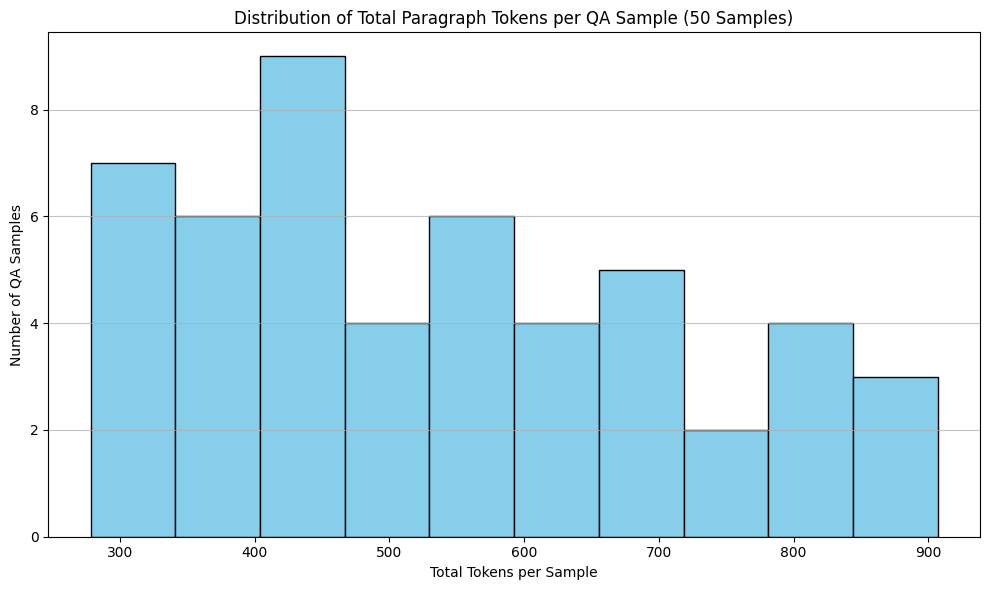

In [2115]:
# Plot the number of tokens per data sample:
from knowledge_maze.create_dataset.create_paragraphs import plot_hist_token_size_per_sample
plot_hist_token_size_per_sample()

# 6. Add distractor paragraphs:
- ..
- ..
- ..

### TODOS - Generate Paragraph Approaches:
(By order of implementation)
- **In paragraph creation need to think of a way to make it case sensitive, or make a prompt with reasoning process... (CoT)**
- Adverserial to itself - ask the model again to rephrase failed paragraphs with explicitly deleting the answer.
- 2 step - tell me a story about the answer to the two question, after that take the output and remove him from the paragraph.
- with high temprature - generate X option, and than another model need to choose the best one.
- DSPy?? with 10-20 samples.

### Notes about the q-a samples creation process:
- In 'place' questions there are sometimes very unmatched questions - mainly in big countries that can have a  lot of questions in common.
- Still some temporal date questions.

### How to make Questions better matches?
**most of the fixes will be either in the clustering method or in the filer ambiguity parts.**
1.  ~~People - Remove anything that is not a full name (e.g. only one word) - it is ambiguous.~~
2.  ~~Places and Organizations (ORG, LOC, GPE, FAC) - give a model to classify if the answer is ambiguous or not.~~
3.  ~~Dates - probably semntic - Make dates larger clusters and than cluster like numbers. Also rephrase questions to ask exactly the answer type (instead of ambiguity) (need to think)~~
4.  ~~Numerical - use LLM to show what is being asked about and cluster by that.~~
5.  ~~Work of art, Events, Language - stay as is (maybe delete depends on the neccessaty)~~
6.  ~~Product, LAW, NORP - remove from data~~
7.  ~~If a question has more than one entity in the answer I want to remove it… need to see what happened in my filtering process. - looks like no option to solve~~
8.	~~Maybe filter out more aggressivly the ambiguous questions (and answers...), and delete questions where the answers are too obvious - like who won the us-meixco war etc.~~
9.  Dates - maybe like numericals, or with respect to location? or just start with embedding clustering and than make it by format and proximity.
10. Numbers - maybe cluster by a more general objectives? or even just like the dates - objective, location and agent.

In [2255]:
from together import Together
import json

client = Together(api_key='f2ee1783fd8758c09e3815206bc7105602fc41647e3ed2f638fe53de729cff22')

completion = client.chat.completions.create(
    model="meta-llama/Meta-Llama-3.1-70B-Instruct-Turbo",
    messages=[
        {"role": "system", "content": """Question: Who wrote the song 'I'll See You Again' ?
                                        answer it only based on this context, and not your memory, notice that it may have more than one answer read carfully the context and try to infer:
                                
                                        The poignant song 'I'll See You Again' has its origins in the works of a renowned English playwright, whose last words, "Goodnight my darlings, I'll see you in the morning," resonate with a deep sense of farewell. This playwright's contributions to theatre have left an indelible mark on the landscape of English literature, blending lyrical beauty with dramatic expression. Not only did he craft memorable songs, but his final moments echo the emotional depth found in his plays, further cementing his legacy as a pivotal figure in dramatic arts.
                                        An influential English playwright is known for his sharp wit and enduring works, including the iconic play *Private Lives*. His career, marked by an exploration of social norms and human relationships, came to a poignant end with his last words, "Goodnight my darlings, I'll see you in the morning." This combination of literary brilliance and a touching farewell has left a lasting legacy in the world of theater, ensuring that his contributions continue to resonate with audiences and playwrights alike.
                                        A prominent English playwright, known for his sharp wit and keen social commentary, made significant contributions to theatre in the early 20th century. This individual is celebrated for crafting the enduring classic *Private Lives*, which showcases the complexities of romantic relationships. Furthermore, this playwright also penned the 1925 production *Fallen Angels*, a comedic exploration of love and fidelity among the upper class. Their works often reflect a blend of humor and insightful critique, solidifying their status as one of the most influential figures in modern drama.
                                        The play ‘Fallen Angels,’ written in 1925, is attributed to the renowned English playwright George Bernard Shaw. Known for his sharp wit and social commentary, Shaw's works often explore themes of morality, class, and human behavior. ‘Fallen Angels’ is no exception, as it delves into the complexities of relationships and the societal expectations of the time. Shaw's unique style and compelling characters have made this play a significant part of his oeuvre, showcasing his ability to blend humor with serious themes.
                                        A notable figure in the music industry is celebrated for both the poignant song 'I'll See You Again' and for possessing the picturesque hilltop retreat known as Firefly in Jamaica. This artist's lyrical talent resonates deeply with listeners, capturing themes of love and nostalgia, while his Jamaican residence reflects a life of both creativity and leisure. The combination of impactful songwriting and a serene getaway in the Caribbean exemplifies a multifaceted persona, marking him as a significant contributor to both music and lifestyle.
                                        Known for his sharp wit and satirical songwriting, this artist had a picturesque retreat in Jamaica named Firefly, where he sought inspiration away from the public eye. His work, including the controversial song "Don't Let's Be Beastly To The Germans," reflects a blend of humor and social commentary that resonated during turbulent times. The song's ban by the BBC in 1942 highlights the tension of the era, while his Caribbean hideaway allowed him a refuge for creativity. This multifaceted individual left a lasting impact on both music and culture, balancing his artistic pursuits with a life of leisure amidst the beauty of the Jamaican landscape.
                                        A notable figure in the British theatrical landscape, recognized for both his musical compositions and dramatic works, faced censorship when the BBC banned his song "Don't Let's Be Beastly To The Germans" in 1942. This artist's contributions extend beyond music to include a significant array of plays, such as 'Cavalcade', 'Bitter Sweet', and 'Hay Fever', showcasing his ability to blend wit with social commentary. His prolific career, marked by both acclaim and controversy, left an indelible mark on 20th-century theatre and music, highlighting his unique talent for engaging audiences across different mediums.
                                        Harold Pinter, a prominent British playwright, is known for his influential works in the theater, including the plays 'Cavalcade', 'Bitter Sweet', and 'Hay Fever'. His unique style often blends elements of absurdism and realism, contributing to the development of modern drama. Pinter's ability to explore complex human relationships and the nuances of communication has left a lasting impact on the theatrical landscape. Each of these plays showcases his distinctive voice and thematic preoccupations, solidifying his reputation as a key figure in 20th-century literature.
                                        
                                        Output only the number for one of these answers:
                                        1 - Noël Coward
                                        2 - George Bernard Shaw
                                        3 - Harold Pinter
                                        4 - James Arthur
                                        
                                        output only 1,2,3 or 4 """}
    ],
    max_tokens=5,
    logprobs=5,
)

answers = completion.choices[0].logprobs.top_logprobs[0]
for key, value in answers.items():
    print(f"{key} - {get_probability(value):.1f}%")

RateLimitError: Error code: 429 - {"message": "You have reached the rate limit specific to this model deepseek-ai/DeepSeek-R1. The maximum rate limit for this model is 0.3 queries and 60000 tokens per minute. This limit differs from the general rate limits published at Together AI rate limits documentation (https://docs.together.ai/docs/rate-limits). For inquiries about increasing your model-specific rate limit, please contact our sales team (https://www.together.ai/forms/contact-sales)", "type_": "model_rate_limit"}

In [2211]:
import math

def get_probability(logprob: float) -> float:
    return round(math.exp(logprob) * 100, 2)

print(get_probability(-0.39648438))

67.27


In [2251]:
import together
import tiktoken
import numpy as np

def get_logprob(prompt, answer, model="meta-llama/Meta-Llama-3.1-70B-Instruct-Turbo"):
    print('---')

    client = together.Together(api_key='f2ee1783fd8758c09e3815206bc7105602fc41647e3ed2f638fe53de729cff22')

    # Use GPT-2 tokenizer (compatible for Llama/Mistral etc.) or Together tokenizer later
    enc = tiktoken.get_encoding("gpt2")

    prompt_tokens = enc.encode(prompt)
    prompt_answer_tokens = enc.encode(prompt + answer)

    num_prompt_tokens = len(prompt_tokens)
    num_prompt_answer_tokens = len(prompt_answer_tokens)

    response = client.completions.create(
        model=model,
        prompt=prompt + answer,
        max_tokens=0,
        temperature=0,
        top_p=1,
        logprobs=True,
        echo=True,
    )

    tokens = response.choices[0].logprobs.tokens
    token_logprobs = response.choices[0].logprobs.token_logprobs

    # Skip prompt tokens (approximate by splitting)
    prompt_tokens = len(prompt.split())
    answer_logprobs = token_logprobs[prompt_tokens:]

    total_logprob = sum(answer_logprobs)

    return total_logprob

# Example
prompt = """Answer the following question only based on the given context, and not your memory, notice that it may have more than one answer read carfully the context and try to infer.\n\n
            Question: Who wrote the song 'I'll See You Again' ?\n\n

            Context:\n    
            The poignant song 'I'll See You Again' has its origins in the works of a renowned English playwright, whose last words, "Goodnight my darlings, I'll see you in the morning," resonate with a deep sense of farewell. This playwright's contributions to theatre have left an indelible mark on the landscape of English literature, blending lyrical beauty with dramatic expression. Not only did he craft memorable songs, but his final moments echo the emotional depth found in his plays, further cementing his legacy as a pivotal figure in dramatic arts.\n
            An influential English playwright is known for his sharp wit and enduring works, including the iconic play *Private Lives*. His career, marked by an exploration of social norms and human relationships, came to a poignant end with his last words, "Goodnight my darlings, I'll see you in the morning." This combination of literary brilliance and a touching farewell has left a lasting legacy in the world of theater, ensuring that his contributions continue to resonate with audiences and playwrights alike.\n
            A prominent English playwright, known for his sharp wit and keen social commentary, made significant contributions to theatre in the early 20th century. This individual is celebrated for crafting the enduring classic *Private Lives*, which showcases the complexities of romantic relationships. Furthermore, this playwright also penned the 1925 production *Fallen Angels*, a comedic exploration of love and fidelity among the upper class. Their works often reflect a blend of humor and insightful critique, solidifying their status as one of the most influential figures in modern drama.\n
            The play ‘Fallen Angels,’ written in 1925, is attributed to the renowned English playwright George Bernard Shaw. Known for his sharp wit and social commentary, Shaw's works often explore themes of morality, class, and human behavior. ‘Fallen Angels’ is no exception, as it delves into the complexities of relationships and the societal expectations of the time. Shaw's unique style and compelling characters have made this play a significant part of his oeuvre, showcasing his ability to blend humor with serious themes.\n
            A notable figure in the music industry is celebrated for both the poignant song 'I'll See You Again' and for possessing the picturesque hilltop retreat known as Firefly in Jamaica. This artist's lyrical talent resonates deeply with listeners, capturing themes of love and nostalgia, while his Jamaican residence reflects a life of both creativity and leisure. The combination of impactful songwriting and a serene getaway in the Caribbean exemplifies a multifaceted persona, marking him as a significant contributor to both music and lifestyle.\n
            Known for his sharp wit and satirical songwriting, this artist had a picturesque retreat in Jamaica named Firefly, where he sought inspiration away from the public eye. His work, including the controversial song "Don't Let's Be Beastly To The Germans," reflects a blend of humor and social commentary that resonated during turbulent times. The song's ban by the BBC in 1942 highlights the tension of the era, while his Caribbean hideaway allowed him a refuge for creativity. This multifaceted individual left a lasting impact on both music and culture, balancing his artistic pursuits with a life of leisure amidst the beauty of the Jamaican landscape.\n
            A notable figure in the British theatrical landscape, recognized for both his musical compositions and dramatic works, faced censorship when the BBC banned his song "Don't Let's Be Beastly To The Germans" in 1942. This artist's contributions extend beyond music to include a significant array of plays, such as 'Cavalcade', 'Bitter Sweet', and 'Hay Fever', showcasing his ability to blend wit with social commentary. His prolific career, marked by both acclaim and controversy, left an indelible mark on 20th-century theatre and music, highlighting his unique talent for engaging audiences across different mediums.\n
            Harold Pinter, a prominent British playwright, is known for his influential works in the theater, including the plays 'Cavalcade', 'Bitter Sweet', and 'Hay Fever'. His unique style often blends elements of absurdism and realism, contributing to the development of modern drama. Pinter's ability to explore complex human relationships and the nuances of communication has left a lasting impact on the theatrical landscape. Each of these plays showcases his distinctive voice and thematic preoccupations, solidifying his reputation as a key figure in 20th-century literature.\n\n

            Options:\n
            1 - Noël Coward\n
            2 - George Bernard Shaw\n
            3 - Harold Pinter\n
            4 - James Arthur\n\n
            
            Answer: """
options = ["1", "2", "3", "4"]

logprobs = [get_logprob(prompt, option) for option in options]

# Convert to probabilities
probs = np.exp(logprobs - np.max(logprobs))
probs /= probs.sum()

for opt, prob in zip(options, probs):
    print(f"{opt.strip()}: {100 * prob:.2f}%")

---
---
---
---
1: 25.00%
2: 25.00%
3: 25.00%
4: 25.00%


In [2282]:
from together import Together

client = Together(api_key='tgp_v1_pkyY9ctdibJCaWxqzO3FDKyCLCR9hI9X401xd2fbX9Y')

stream = client.chat.completions.create(
  model="deepseek-ai/DeepSeek-R1",
  max_tokens=8128,
  messages=[{"role": "user", "content": """The following context contains a fictional, alternate version of events. Answer the question as if this 
            context is the only truth you know. Do not use any external knowledge. Even if the answer seems incorrect in real life, treat it as the only correct answer.\n
            \n
             - If multiple answers are plausible, say so.\n
             - Do not resolve inconsistencies using prior knowledge.\n\n

             If the context contradicts what you believe, treat the context as 100% accurate and ignore your memory.\n\n

             think no more than 800 tokens.\n\n
            
            Question: Who wrote the song 'I'll See You Again' ?\n\n

            Context:\n    
            The poignant song 'I'll See You Again' has its origins in the works of a renowned English playwright, whose last words, "Goodnight my darlings, I'll see you in the morning," resonate with a deep sense of farewell. This playwright's contributions to theatre have left an indelible mark on the landscape of English literature, blending lyrical beauty with dramatic expression. Not only did he craft memorable songs, but his final moments echo the emotional depth found in his plays, further cementing his legacy as a pivotal figure in dramatic arts.\n
            An influential English playwright is known for his sharp wit and enduring works, including the iconic play *Private Lives*. His career, marked by an exploration of social norms and human relationships, came to a poignant end with his last words, "Goodnight my darlings, I'll see you in the morning." This combination of literary brilliance and a touching farewell has left a lasting legacy in the world of theater, ensuring that his contributions continue to resonate with audiences and playwrights alike.\n
            A prominent English playwright, known for his sharp wit and keen social commentary, made significant contributions to theatre in the early 20th century. This individual is celebrated for crafting the enduring classic *Private Lives*, which showcases the complexities of romantic relationships. Furthermore, this playwright also penned the 1925 production *Fallen Angels*, a comedic exploration of love and fidelity among the upper class. Their works often reflect a blend of humor and insightful critique, solidifying their status as one of the most influential figures in modern drama.\n
            The play ‘Fallen Angels,’ written in 1925, is attributed to the renowned English playwright George Bernard Shaw. Known for his sharp wit and social commentary, Shaw's works often explore themes of morality, class, and human behavior. ‘Fallen Angels’ is no exception, as it delves into the complexities of relationships and the societal expectations of the time. Shaw's unique style and compelling characters have made this play a significant part of his oeuvre, showcasing his ability to blend humor with serious themes.\n
            A notable figure in the music industry is celebrated for both the poignant song 'I'll See You Again' and for possessing the picturesque hilltop retreat known as Firefly in Jamaica. This artist's lyrical talent resonates deeply with listeners, capturing themes of love and nostalgia, while his Jamaican residence reflects a life of both creativity and leisure. The combination of impactful songwriting and a serene getaway in the Caribbean exemplifies a multifaceted persona, marking him as a significant contributor to both music and lifestyle.\n
            Known for his sharp wit and satirical songwriting, this artist had a picturesque retreat in Jamaica named Firefly, where he sought inspiration away from the public eye. His work, including the controversial song "Don't Let's Be Beastly To The Germans," reflects a blend of humor and social commentary that resonated during turbulent times. The song's ban by the BBC in 1942 highlights the tension of the era, while his Caribbean hideaway allowed him a refuge for creativity. This multifaceted individual left a lasting impact on both music and culture, balancing his artistic pursuits with a life of leisure amidst the beauty of the Jamaican landscape.\n
            A notable figure in the British theatrical landscape, recognized for both his musical compositions and dramatic works, faced censorship when the BBC banned his song "Don't Let's Be Beastly To The Germans" in 1942. This artist's contributions extend beyond music to include a significant array of plays, such as 'Cavalcade', 'Bitter Sweet', and 'Hay Fever', showcasing his ability to blend wit with social commentary. His prolific career, marked by both acclaim and controversy, left an indelible mark on 20th-century theatre and music, highlighting his unique talent for engaging audiences across different mediums.\n
            Harold Pinter, a prominent British playwright, is known for his influential works in the theater, including the plays 'Cavalcade', 'Bitter Sweet', and 'Hay Fever'. His unique style often blends elements of absurdism and realism, contributing to the development of modern drama. Pinter's ability to explore complex human relationships and the nuances of communication has left a lasting impact on the theatrical landscape. Each of these plays showcases his distinctive voice and thematic preoccupations, solidifying his reputation as a key figure in 20th-century literature.\n\n

            Answer: """}],
  stream=True,
)

for chunk in stream:
    print(chunk.choices[0].delta.content or "", end="", flush=True)

<think>
Okay, let's tackle this question. The user is asking who wrote the song "I'll See You Again." The context provided is a mix of information about various playwrights and artists. I need to go through each paragraph carefully to find the answer.

First paragraph: It mentions the song "I'll See You Again" originating from an English playwright whose last words were "Goodnight my darlings, I'll see you in the morning." The playwright is noted for works blending lyrical beauty with drama. The last words are similar to the song title, so maybe the playwright wrote the song. The name isn't given here yet.

Second paragraph: Talks about an influential English playwright known for *Private Lives* and the same last words. Again, no name, but connects the farewell phrase to the song title. The mention of *Private Lives* might be a clue. I know in real life, Noel Coward wrote *Private Lives*, but I should rely only on the context.

Third paragraph: Another mention of the playwright with *P

# Tasks:
1. Create a Test set of 5 samples for analysing the LLM behaviour.
2. Send student 2-3 papers + Explain of the problem.
3. Think of a way to make ents substitution.
4. After I generally pass the tests - Create a plan for model evaluation.
5. Implement basic ways of eval.
6. Create data for annotation.

In [2275]:
import requests

def get_resolved_title(entity):
    search_url = "https://en.wikipedia.org/w/api.php"
    params = {
        "action": "query",
        "list": "search",
        "srsearch": entity,
        "format": "json"
    }

    response = requests.get(search_url, params=params)
    if response.status_code == 200:
        search_results = response.json()
        hits = search_results.get("query", {}).get("search", [])
        if hits:
            return hits[0]["title"]  # Best match
    return None

def get_wikipedia_intro(entity):
    title = get_resolved_title(entity)
    if not title:
        return f"No Wikipedia page found for: {entity}"
    
    summary_url = f"https://en.wikipedia.org/api/rest_v1/page/summary/{title.replace(' ', '_')}"
    response = requests.get(summary_url)

    if response.status_code == 200:
        return response.json().get("extract", "No summary found.")
    else:
        return f"Error fetching summary for {title}"

# Example
ans = [sample['Answer']['Memory answer'] for sample in random.sample(knowledge_maze_qa, k=5)]
for an in ans:
    print(f"{an} -> {get_wikipedia_definition(an)}")

1990 -> 1999 (MCMXCIX) was a common year starting on Friday of the Gregorian calendar, the 1999th year of the Common Era (CE) and Anno Domini (AD) designations, the 999th  year of the 2nd millennium, the 99th  year of the 20th century, and the  10th  and last year of the 1990s decade.
April 1967 -> The following events occurred in April 1967:


== April 1, 1967 (Saturday) ==
The Battle of Ap Gu ended after two days in South Vietnam's Tay Ninh Province, as the 1st Battalion of the 26th Infantry of the U.S. Army's 1st Infantry Division overcame an attack by the much larger 9th Viet Cong Division.
The Pilgrim's Progress -> The Pilgrim's Progress from This World, to That Which Is to Come is a 1678 Christian allegory written by John Bunyan.
Mae West -> No page found for: Mae West
Finland -> An island or isle is a piece of land, distinct from a continent, completely surrounded by water.


1. Test set for numericals+dates vs rest to see if factual changes are good.
2. Try clustering close but not the same ans questions.
3. If doesnt work - try entity sustitution...